# prophet forecasting

forecasting daily sales for our 6 product categories using prophet, evaluating on the last 60 days with mae and rmse, and predicting the next 30 days.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error


Importing plotly failed. Interactive plots will not work.


### loading the data

loading our clean daily sales dataset from notebook 02.


In [2]:
df = pd.read_csv("data/processed/daily_category_sales.csv")
df["date"] = pd.to_datetime(df["date"])

print("shape:", df.shape)
df.head()


shape: (4404, 3)


,date,category,units_sold
0,2018-09-20,Accessories,2194
1,2018-09-21,Accessories,2269
2,2018-09-22,Accessories,836
3,2018-09-23,Accessories,2086
4,2018-09-24,Accessories,2092


### train-test split

we train on the first 674 days (up to 2020-07-24) and test on the last 60 days (2020-07-25 to 2020-09-22).


In [3]:
split_date = df["date"].max() - pd.Timedelta(days=60)

train = df[df["date"] < split_date]
test = df[df["date"] >= split_date]

print("train:", train["date"].min().date(), "to", train["date"].max().date(), f"({train['date'].nunique()} days)")
print("test: ", test["date"].min().date(), "to", test["date"].max().date(), f"({test['date'].nunique()} days)")


train: 2018-09-20 to 2020-07-23 (673 days)
test:  2020-07-24 to 2020-09-22 (61 days)


### training prophet and evaluating each category

we train a model for each category, predict the 60-day test set, and calculate mae and rmse.


In [4]:
categories = [
    "Garment Upper body",
    "Garment Lower body",
    "Garment Full body",
    "Swimwear",
    "Underwear",
    "Accessories"
]

results = []
test_preds = {}

for cat in categories:
    cat_train = train[train["category"] == cat][["date", "units_sold"]].rename(columns={"date": "ds", "units_sold": "y"})
    cat_test = test[test["category"] == cat][["date", "units_sold"]].rename(columns={"date": "ds", "units_sold": "y"})
    
    m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    m.fit(cat_train)
    
    future = m.make_future_dataframe(periods=len(cat_test), freq="D")
    forecast = m.predict(future)
    
    pred = forecast.tail(len(cat_test))["yhat"].values
    actual = cat_test["y"].values
    test_preds[cat] = pred
    
    mae = mean_absolute_error(actual, pred)
    rmse = root_mean_squared_error(actual, pred)
    
    results.append({
        "category": cat,
        "avg_daily_sales": round(actual.mean(), 1),
        "mae": round(mae, 1),
        "rmse": round(rmse, 1),
        "mae_pct": round((mae / actual.mean()) * 100, 1)
    })

eval_df = pd.DataFrame(results)
eval_df


C:\Users\dumbgesh\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


01:25:03 - cmdstanpy - INFO - Chain [1] start processing


01:25:03 - cmdstanpy - INFO - Chain [1] done processing


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


01:25:03 - cmdstanpy - INFO - Chain [1] start processing


01:25:03 - cmdstanpy - INFO - Chain [1] done processing


... (9 outputs left out)

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


01:25:05 - cmdstanpy - INFO - Chain [1] start processing


01:25:05 - cmdstanpy - INFO - Chain [1] done processing


,category,avg_daily_sales,mae,rmse,mae_pct
0,Garment Upper body,15608.3,3924.5,4909.3,25.1
1,Garment Lower body,8649.0,1708.8,2188.5,19.8
2,Garment Full body,4643.6,1002.5,1338.8,21.6
3,Swimwear,2580.3,1830.8,2092.3,71.0
4,Underwear,3150.3,495.2,659.8,15.7
5,Accessories,2015.9,453.3,560.6,22.5


### comparing model performance

underwear had the lowest error (15.7%) because demand stays steady throughout the year.
swimwear was the hardest to predict (71.0% error) because demand dropped sharply during august and september as summer ended.


### actual vs predicted plots

let's plot actual sales against predicted sales on the 60-day test set.


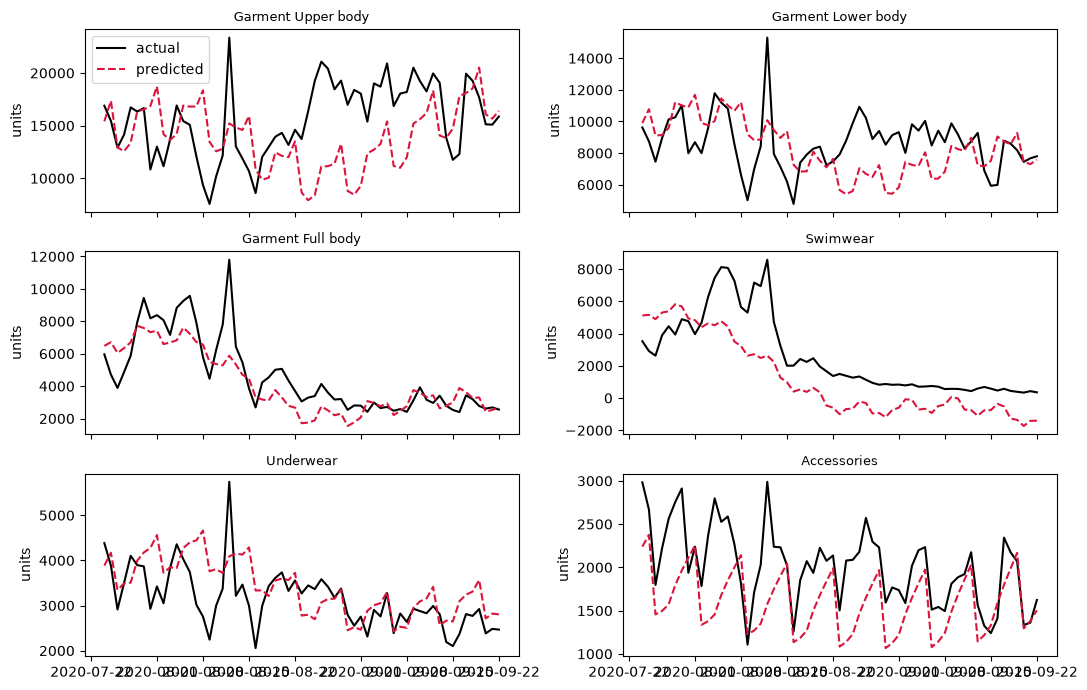

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(11, 7), sharex=True)
axes = axes.flatten()

for i, cat in enumerate(categories):
    test_dates = test[test["category"] == cat]["date"]
    actual = test[test["category"] == cat]["units_sold"]
    pred = test_preds[cat]
    
    axes[i].plot(test_dates, actual, label="actual", color="black")
    axes[i].plot(test_dates, pred, label="predicted", color="crimson", linestyle="--")
    axes[i].set_title(cat, fontsize=9)
    axes[i].set_ylabel("units")
    if i == 0:
        axes[i].legend()

plt.tight_layout()
plt.show()


### future 30-day forecast

now we retrain each model on the entire dataset (all 734 days) and forecast the next 30 days (2020-09-23 to 2020-10-22).
note: these are model forecasts into the future, not verified actual sales.


In [6]:
future_rows = []

for cat in categories:
    sub = df[df["category"] == cat][["date", "units_sold"]].rename(columns={"date": "ds", "units_sold": "y"})
    
    m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    m.fit(sub)
    
    future = m.make_future_dataframe(periods=30, freq="D")
    forecast = m.predict(future)
    
    next30 = forecast.tail(30)[["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()
    next30["category"] = cat
    next30.rename(columns={"ds": "date", "yhat": "forecast_units", "yhat_lower": "forecast_lower", "yhat_upper": "forecast_upper"}, inplace=True)
    next30["forecast_units"] = next30["forecast_units"].clip(lower=0).round(1)
    future_rows.append(next30)

future_df = pd.concat(future_rows, ignore_index=True)
future_df.to_csv("data/processed/future_sales_forecast.csv", index=False)
print("saved data/processed/future_sales_forecast.csv with", len(future_df), "rows")
future_df.head()


01:25:07 - cmdstanpy - INFO - Chain [1] start processing


01:25:07 - cmdstanpy - INFO - Chain [1] done processing


01:25:07 - cmdstanpy - INFO - Chain [1] start processing


01:25:07 - cmdstanpy - INFO - Chain [1] done processing


01:25:07 - cmdstanpy - INFO - Chain [1] start processing


01:25:07 - cmdstanpy - INFO - Chain [1] done processing


... (4 outputs left out)

01:25:08 - cmdstanpy - INFO - Chain [1] start processing


01:25:09 - cmdstanpy - INFO - Chain [1] done processing


saved data/processed/future_sales_forecast.csv with 180 rows


,date,forecast_units,forecast_lower,forecast_upper,category
0,2020-09-23,19035.7,11614.824644,26810.275788,Garment Upper body
1,2020-09-24,19129.1,10978.095163,26836.913942,Garment Upper body
2,2020-09-25,19254.0,11208.946072,27639.645430,Garment Upper body
3,2020-09-26,20963.7,13302.868167,28784.575474,Garment Upper body
4,2020-09-27,16634.2,8068.343442,24478.545268,Garment Upper body


### plotting the future forecast

let's see what the next 30 days of forecasted sales look like.


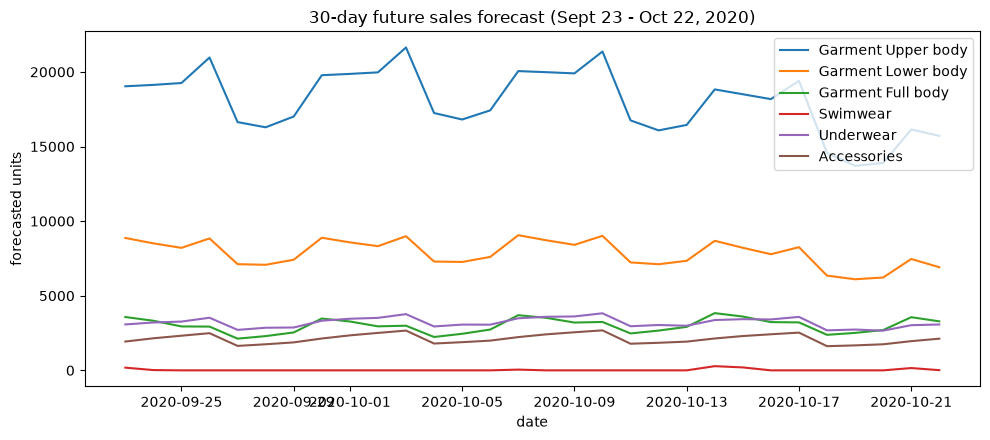

In [7]:
plt.figure(figsize=(10, 4.5))
for cat in categories:
    sub = future_df[future_df["category"] == cat]
    plt.plot(pd.to_datetime(sub["date"]), sub["forecast_units"], label=cat)

plt.title("30-day future sales forecast (Sept 23 - Oct 22, 2020)")
plt.xlabel("date")
plt.ylabel("forecasted units")
plt.legend()
plt.tight_layout()
plt.show()


### summary

we evaluated prophet models for all 6 categories using mae and rmse, and generated future forecasts for the next 30 days.
